In [1]:
import sys, json, joblib
from pathlib import Path
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

ROOT_DIR = Path(r"c:\Project\napasloka\napasloka")

if str(ROOT_DIR) not in sys.path:
    sys.path.insert(0, str(ROOT_DIR))

import pandas as pd

summary_path = ROOT_DIR / "artifacts" / "summary_metrics.csv"
df_summary = pd.read_csv(summary_path)
df_summary


,location,pollutant,scenario,algorithm,mae,rmse,mape,r2,training_time_seconds,prediction_time_seconds,best_params
0,taman-kamal,CO,scenario_1,xgboost,63.622424,95.122871,6.227183,0.981961,9.730577,0.006736,"{'n_estimators': 300, 'max_depth': 6, 'learnin..."
1,taman-kamal,CO,scenario_1,lightgbm,62.475965,92.168714,6.145671,0.983064,5.649717,0.022104,"{'n_estimators': 500, 'max_depth': 9, 'learnin..."
2,taman-kamal,CO,scenario_2,xgboost,69.062951,100.652386,7.033787,0.979803,13.110022,0.006275,"{'n_estimators': 300, 'max_depth': 6, 'learnin..."
3,taman-kamal,CO,scenario_2,lightgbm,65.859890,96.135442,6.742276,0.981575,7.262533,0.021443,"{'n_estimators': 500, 'max_depth': 9, 'learnin..."
4,taman-kamal,CO2,scenario_1,xgboost,1.187560,1.654335,0.255770,0.982027,1.528648,0.006892,"{'n_estimators': 300, 'max_depth': 6, 'learnin..."
...,...,...,...,...,...,...,...,...,...,...,...
115,cibinong,CO,scenario_2,lightgbm,58.531201,82.637753,5.273384,0.981507,8.227737,0.021661,"{'n_estimators': 500, 'max_depth': 9, 'learnin..."
116,cibinong,CO2,scenario_1,xgboost,2.205892,3.112544,0.455648,0.985864,1.852382,0.006727,"{'n_estimators': 300, 'max_depth': 6, 'learnin..."
117,cibinong,CO2,scenario_1,lightgbm,2.127231,2.991223,0.439458,0.986944,4.850213,0.020659,"{'n_estimators': 500, 'max_depth': 9, 'learnin..."
118,cibinong,CO2,scenario_2,xgboost,2.216560,3.189861,0.456774,0.985152,10.274093,0.005932,"{'n_estimators': 300, 'max_depth': 6, 'learnin..."


### Global Feature Importance

In [14]:
# 1. Agregasi nilai SHAP dari seluruh 120 eksperimen
shap_files = list(ROOT_DIR.glob("artifacts/experiments/*/*/*/*/shap_global.csv"))
records = []
for p in shap_files:
    parts = p.parts
    loc, pol, scn, algo = parts[-5], parts[-4], parts[-3], parts[-2]
    df_s = pd.read_csv(p)

    p_gain = p.parent / "feature_importance.csv"
    if p_gain.exists():
        df_g = pd.read_csv(p_gain)
        df = pd.merge(df_s, df_g, on="feature")
    else:
        df = df_s
        df["importance"] = 0.0

    df["location"] = loc
    df["pollutant"] = pol.upper()
    df["scenario"] = scn
    df["algorithm"] = algo
    records.append(df)
df_all = pd.concat(records, ignore_index=True)
df_all

,feature,mean_absolute_shap,importance,location,pollutant,scenario,algorithm
0,carbon_monoxide_lag_1h,587.435004,0.936130,cibinong,CO,scenario_1,lightgbm
1,carbon_monoxide_lag_2h,218.591071,0.046841,cibinong,CO,scenario_1,lightgbm
2,carbon_monoxide_lag_3h,65.477619,0.017029,cibinong,CO,scenario_1,lightgbm
3,carbon_monoxide_lag_1h,567.163200,0.939549,cibinong,CO,scenario_1,xgboost
4,carbon_monoxide_lag_2h,191.218920,0.044794,cibinong,CO,scenario_1,xgboost
...,...,...,...,...,...,...,...
1075,relative_humidity_2m_lag_2h,0.075847,0.000292,tol-serpong-interchange,CO2,scenario_2,xgboost
1076,wind_speed_100m_lag_2h,0.052734,0.000471,tol-serpong-interchange,CO2,scenario_2,xgboost
1077,rain_lag_1h,0.043644,0.000185,tol-serpong-interchange,CO2,scenario_2,xgboost
1078,rain_lag_3h,0.029511,0.000206,tol-serpong-interchange,CO2,scenario_2,xgboost


In [15]:
# 2. Buat Tabel Top 5 Fitur Skenario 2
# Agregasi Polutan CO
sub_co = df_all[(df_all["pollutant"] == "CO") & (df_all["scenario"] == "scenario_2")]
top_co = sub_co.groupby("feature")[["mean_absolute_shap", "importance"]].mean()
top_co["Gain CO (%)"] = (top_co["importance"] * 100).round(2)
top_co["Mean |SHAP| CO (µg/m³)"] = top_co["mean_absolute_shap"].round(2)
top_co = top_co.sort_values(by="Mean |SHAP| CO (µg/m³)", ascending=False).head(5).reset_index()
top_co = top_co[["feature", "Gain CO (%)", "Mean |SHAP| CO (µg/m³)"]]
top_co.columns = ["Fitur CO", "Gain CO (%)", "Mean |SHAP| CO (µg/m³)"]
# Agregasi Polutan CO2
sub_co2 = df_all[(df_all["pollutant"] == "CO2") & (df_all["scenario"] == "scenario_2")]
top_co2 = sub_co2.groupby("feature")[["mean_absolute_shap", "importance"]].mean()
top_co2["Gain CO2 (%)"] = (top_co2["importance"] * 100).round(2)
top_co2["Mean |SHAP| CO2 (ppm)"] = top_co2["mean_absolute_shap"].round(2)
top_co2 = top_co2.sort_values(by="Mean |SHAP| CO2 (ppm)", ascending=False).head(5).reset_index()
top_co2 = top_co2[["feature", "Gain CO2 (%)", "Mean |SHAP| CO2 (ppm)"]]
top_co2.columns = ["Fitur CO2", "Gain CO2 (%)", "Mean |SHAP| CO2 (ppm)"]

tabel_komparasi = pd.concat([top_co, top_co2], axis=1)
display(tabel_komparasi)

,Fitur CO,Gain CO (%),Mean |SHAP| CO (µg/m³),Fitur CO2,Gain CO2 (%),Mean |SHAP| CO2 (ppm)
0,carbon_monoxide_lag_1h,91.33,1066.68,carbon_dioxide_lag_1h,93.47,14.92
1,carbon_monoxide_lag_2h,5.90,385.87,carbon_dioxide_lag_2h,4.04,3.97
2,carbon_monoxide_lag_3h,1.33,67.42,carbon_dioxide_lag_3h,1.06,0.80
3,temperature_2m_lag_3h,0.28,37.40,temperature_2m_lag_1h,0.45,0.67
4,temperature_2m_lag_1h,0.22,21.74,temperature_2m_lag_3h,0.25,0.50


✓ Grafik SHAP disimpan di: gambar_shap_global.png


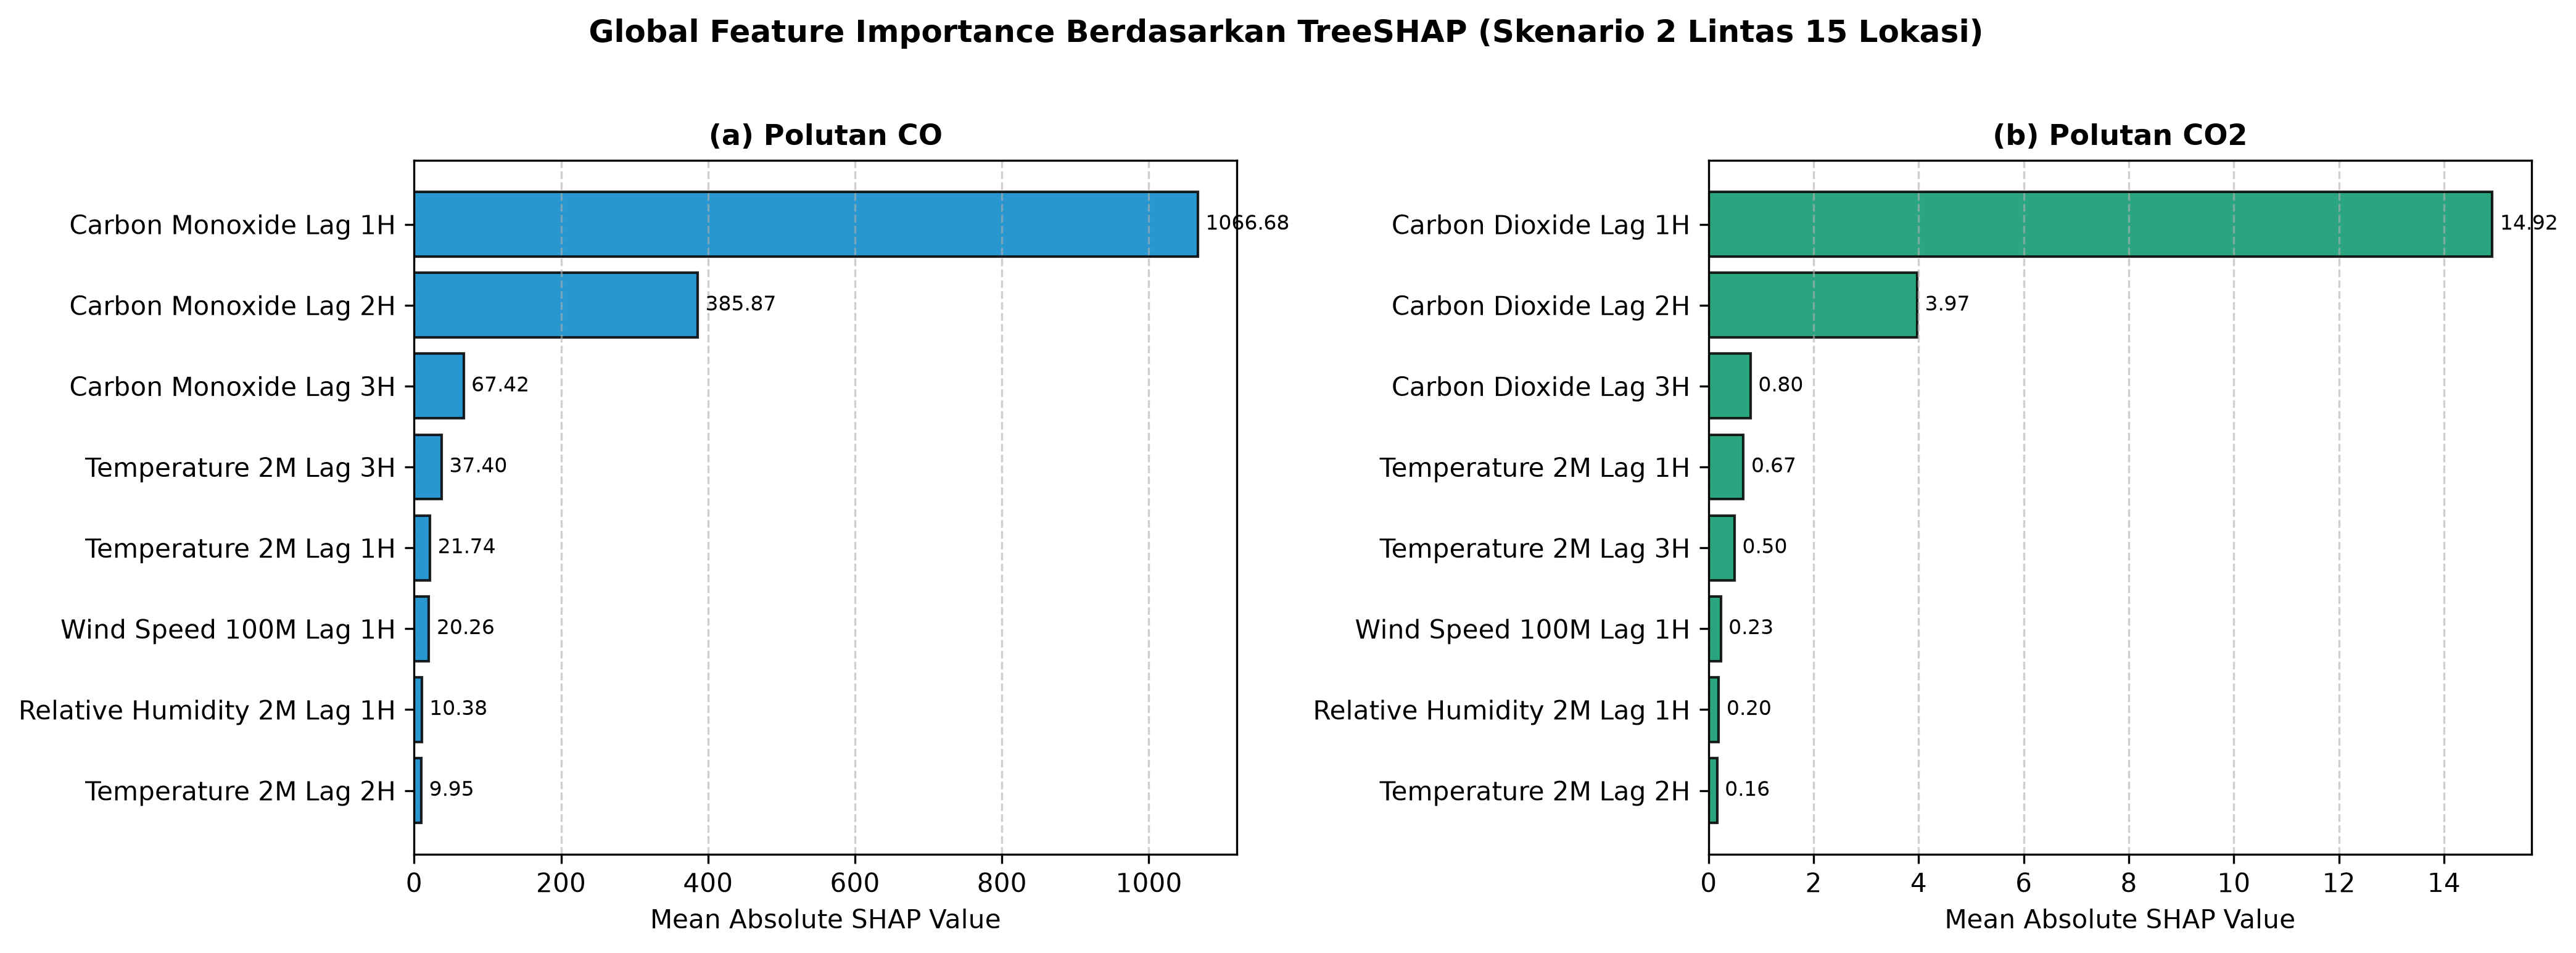

In [16]:
# 3. Visualisasi Horizontal Bar Chart Global Feature Importance
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5), dpi=300)
for ax, pol, color, title in zip([ax1, ax2], ["CO", "CO2"], ["#0284c7", "#059669"], ["(a) Polutan CO", "(b) Polutan CO2"]):
    sub = df_all[(df_all["pollutant"] == pol) & (df_all["scenario"] == "scenario_2")]
    mean_imp = sub.groupby("feature")["mean_absolute_shap"].mean().sort_values(ascending=True).tail(8)
    labels = [f.replace("_", " ").title() for f in mean_imp.index]
    bars = ax.barh(labels, mean_imp.values, color=color, edgecolor="black", alpha=0.85)
    ax.set_title(title, fontsize=11, fontweight="bold")
    ax.set_xlabel("Mean Absolute SHAP Value", fontsize=10)
    ax.grid(axis="x", linestyle="--", alpha=0.6)
    ax.bar_label(bars, fmt="%.2f", padding=3, fontsize=8)
plt.suptitle("Global Feature Importance Berdasarkan TreeSHAP (Skenario 2 Lintas 15 Lokasi)", fontsize=12, fontweight="bold", y=1.02)
plt.tight_layout()
out_shap_img = ROOT_DIR / "artifacts" / "gambar_shap_global.png"
plt.savefig(out_shap_img, dpi=300, bbox_inches="tight")
print(f"✓ Grafik SHAP disimpan di: {out_shap_img.name}")
plt.show()

### Local Feature Importance

In [6]:
import joblib, shap
from backend.app.services.data_service import data_service

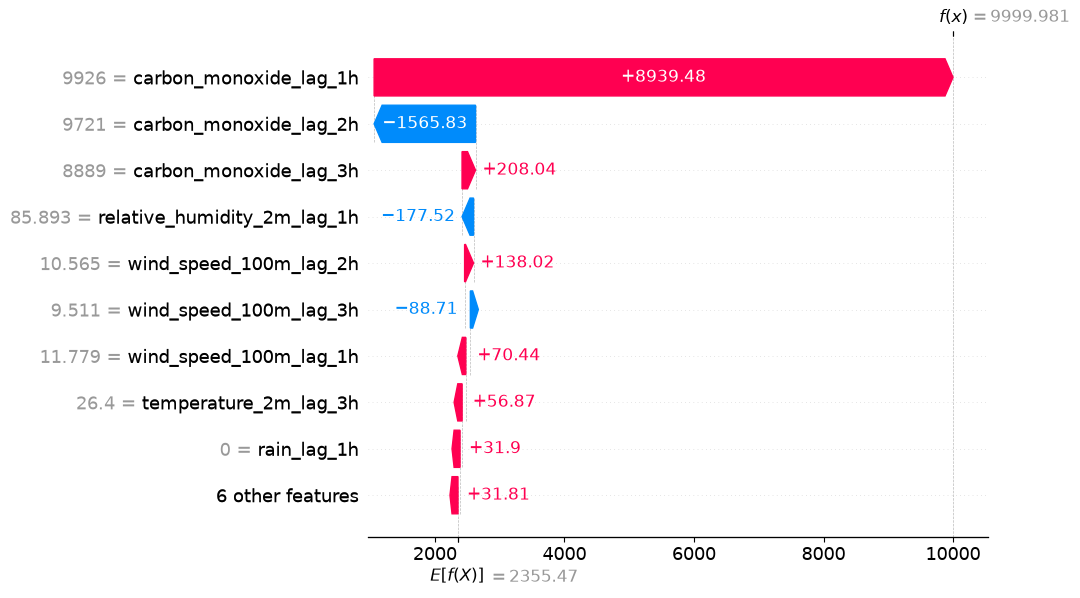

In [ ]:
model = joblib.load(ROOT_DIR / "artifacts/final/petamburan-perkantoran-transjakarta/co/scenario_2/model.joblib")
X_sample, _ = data_service.build_next_hour_features("petamburan-perkantoran-transjakarta", "co", "scenario_2", reference_datetime="2026-06-25T21:00:00+07:00")

explainer = shap.TreeExplainer(model)
shap_values = explainer(X_sample)
shap.plots.waterfall(shap_values[0])